# 손실 함수는 선택이 아니라 결론이다

1. y = f(x) + ε, ε~N(0,σ²) 라면 **MSE** 는 로그우도를 최대화하는 것과 같다(σ 고정).
2. y∈{0,1} ~ Bernoulli(p) 라면 **교차엔트로피**를 최소화하는 p̂ 는 우도를 최대화하는 p̂ 와 같다.
여기서 격자해상도 0.001 이 '완전 일치'의 뜻을 규정한다(같은 격자 위에서는 두 목적함수가 단조관계라 argmin 이 갈리지 않는다 — 격자를 바꾼 '갈린다' 주장은 실측 없이 쓰지 않는다).

In [1]:
import numpy as np, json, pathlib, sys
import matplotlib, matplotlib.pyplot as plt
from IPython import display as _ipd
sys.path.insert(0, str(pathlib.Path.cwd() / 'src'))
import probability as P
import _common  # fig_to_png_b64 (그림 → base64 PNG)
d = json.loads(pathlib.Path('reports/probability.json').read_text(encoding='utf-8'))
print(json.dumps(d['MSE_MLE_동치'], ensure_ascii=False, indent=1))

{
 "기울기_MSE최소": 1.486,
 "기울기_로그우도최대": 1.486,
 "차이": "0.000e+00",
 "σ²_참값추정": 2.2366,
 "해석": "σ 고정 시 두 목적함수는 상수배·상수합의 관계 → 인자가 같다(정규화 상수는 기울기에 무영향)"
}


## 확률 분포 시각화 (원문 제출물 5 — 이 노트북 안에 그림으로)

원문 5-1: 정규분포 **N(0,1)** 과 **N(2,0.5)** 의 PDF 를 하나의 Figure에.
원문 5-2: 베르누이 **B(0.3)** 과 **B(0.7)** 의 PMF 막대그래프를 하나의 Figure에.

베르누이는 **시행 1회**라 k∈{0,1} 두 막대이고 합이 1 이어야 한다. (이전 구현은 `p^k(1-p)^(10-k)`, k=0..10 을 '베르누이'라 라벨링했는데 합이 0.647/0.249 로 1 이 아니었다 → 이항계수 C(10,k) 가 없는 거듭제곱이라 확률분포가 아니다. 감사에서 정정했고, 당초 배우려던 Binomial(10,p) 는 아래에 따로 그린다.)

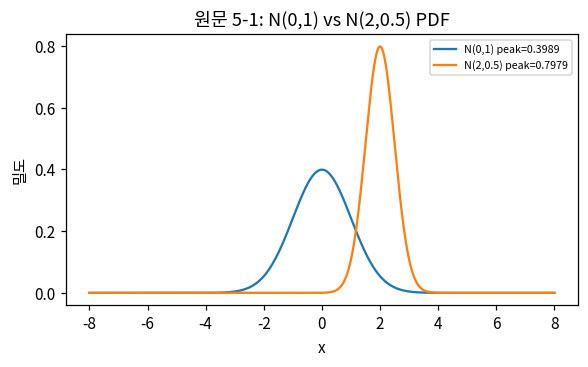

N(0,1): peak=0.398942  ∫[-8,8]=1.000000
N(2,0.5): peak=0.797885  ∫[-8,8]=1.000000


In [2]:
x = np.linspace(-8, 8, 1601)
fig, ax = plt.subplots(figsize=(6.0, 3.2))
for label, (mu, s) in P.NORMALS.items():
    ax.plot(x, P.normal_pdf(x, mu, s), lw=1.5, label=f'{label} peak={P.normal_pdf(mu, mu, s):.4f}')
ax.set_title('원문 5-1: N(0,1) vs N(2,0.5) PDF'); ax.set_xlabel('x'); ax.set_ylabel('밀도'); ax.legend(fontsize=7)
_ipd.display(_ipd.Image(data=P.fig_to_png_bytes(fig), format='png'))
for label, (mu, s) in P.NORMALS.items():
    print(f'{label}: peak={P.normal_pdf(mu,mu,s):.6f}  ∫[-8,8]={np.trapezoid(P.normal_pdf(x,mu,s),x):.6f}')

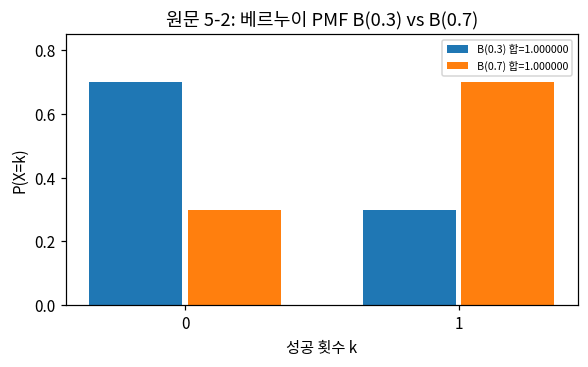

{
 "B(0.3)": {
  "PMF_k0_k1": [
   0.7,
   0.3
  ],
  "합": 1.0,
  "합-1_절대오차": "0.000e+00"
 },
 "B(0.7)": {
  "PMF_k0_k1": [
   0.3,
   0.7
  ],
  "합": 1.0,
  "합-1_절대오차": "0.000e+00"
 }
}
이전 구현(잘못된 라벨)의 막대 합: {"p=0.3": 0.049429, "p=0.7": 0.049429}


In [3]:
k = np.array([0, 1])
fig, ax = plt.subplots(figsize=(6.0, 3.2))
for i, (label, p) in enumerate(P.BERNOULLIS.items()):
    pmf = P.bernoulli_pmf(p)
    ax.bar(k + (-0.18 if i == 0 else 0.18), pmf, width=.34, label=f'{label} 합={pmf.sum():.6f}')
ax.set_xticks([0,1]); ax.set_ylim(0,.85); ax.set_title('원문 5-2: 베르누이 PMF B(0.3) vs B(0.7)')
ax.set_xlabel('성공 횟수 k'); ax.set_ylabel('P(X=k)'); ax.legend(fontsize=7)
_ipd.display(_ipd.Image(data=P.fig_to_png_bytes(fig), format='png'))
print(json.dumps(d['베르누이PMF(원문5-2)'], ensure_ascii=False, indent=1))
print('이전 구현(잘못된 라벨)의 막대 합:', json.dumps(d['베르누이PMF_정정_기록']['이전_구현_막대합'], ensure_ascii=False))

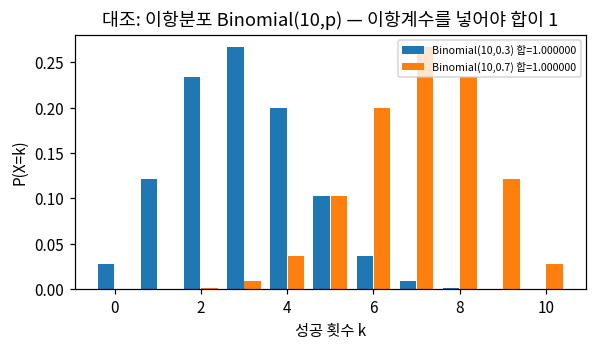

In [4]:
kk = np.arange(0, 11)
fig, ax = plt.subplots(figsize=(6.0, 3.0))
for p, off in ((0.3, -0.2), (0.7, 0.2)):
    ax.bar(kk + off, P.binomial_pmf(10, p), width=.38, label=f'Binomial(10,{p}) 합={P.binomial_pmf(10,p).sum():.6f}')
ax.set_title('대조: 이항분포 Binomial(10,p) — 이항계수를 넣어야 합이 1'); ax.set_xlabel('성공 횟수 k')
ax.set_ylabel('P(X=k)'); ax.legend(fontsize=7)
_ipd.display(_ipd.Image(data=P.fig_to_png_bytes(fig), format='png'))

## 교차엔트로피 = MLE, 그리고 깁스 부등식의 범위

In [5]:
print(json.dumps(d['CE_MLE_동치'], ensure_ascii=False, indent=1))

{
 "로그우도_최대의_p": 0.348,
 "BCE_최소의_p": 0.348,
 "차이": "0.000e+00",
 "표본_평균": 0.348,
 "플러그인_엔트로피": 0.6462,
 "진_엔트로피": 0.647447,
 "참값대_ fitted_교차엔트로피": 0.647455,
 "깁스_성립": true,
 "플러그인_편향": "-0.0012",
 "해석": "CE(=BCE) 최소와 MLE 는 같은 p(0.3480) 를 고른다(격자 0.001 이내 차이 0). 그리고 깁스 부등식은 **참값 기준** CE 0.6475 ≥ H 0.6474 로 성립하고, 표본 자체의 플러그인 엔트로피(0.6462)는 -0.0012 만큼 **아래로** 작다 → '모델 손실이 엔트로피보다 크면 이상하다'는 문장은 표본 기준으로는 틀린다(플러그인 편향)"
}


플러그인(표본 자체) 엔트로피는 참값 엔트로피보다 **작게** 나온다(아래 편향). 그러므로 '손실이 엔트로피보다 크면 이상하다'는 문장은 표본 기준으로는 틀린다.

In [6]:
c = d['CE_MLE_동치']
print('플러그인', c['플러그인_엔트로피'], '참값 H', c['진_엔트로피'], '편향', c['플러그인_편향'],
      '참값 대비 CE', c['참값대_ fitted_교차엔트로피'], '깁스 성립', c['깁스_성립'])

플러그인 0.6462 참값 H 0.647447 편향 -0.0012 참값 대비 CE 0.647455 깁스 성립 True


## softmax: 원문 5-3 (출력 합 = 1.0 ± 1e-6) 과 수치 안정성

안정화(max 차감)의 효과는 **큰 스케일에서만** 관측된다. 작은 스케일에서의 차이는 1e-16 수준이라 검사로서 무의미하다.

In [7]:
z = np.array([1.,2.,3.])
print(json.dumps(d['softmax']['합=1_검증(원문5-3)'], ensure_ascii=False, indent=1))
print('gate 합=1 ±1e-6:', d['softmax']['gate_합=1_±1e-6'], '· 최대 오차', d['softmax']['최대_합-1_절대오차'])
with np.errstate(over='ignore'):
    print('원본 차이', np.max(np.abs(P.softmax(z,False)-P.softmax(z,True))))
    print('×1000 naive', P.softmax(z*1000,False), '\n×1000 safe  ', P.softmax(z*1000,True))

{
 "원본(1,2,3)": {
  "출력": [
   0.090031,
   0.244728,
   0.665241
  ],
  "합-1_절대오차": "1.110e-16",
  "gate_1e-6": true
 },
 "×1000": {
  "출력": [
   0.0,
   0.0,
   1.0
  ],
  "합-1_절대오차": "0.000e+00",
  "gate_1e-6": true
 },
 "큰 음수(-500,0,500)": {
  "출력": [
   0.0,
   0.0,
   1.0
  ],
  "합-1_절대오차": "0.000e+00",
  "gate_1e-6": true
 }
}
gate 합=1 ±1e-6: True · 최대 오차 1.110e-16
원본 차이 1.1102230246251565e-16
×1000 naive [nan nan nan] 
×1000 safe   [0. 0. 1.]


/home/user/work/codyssey-A2-1-mission/src/probability.py:45: RuntimeWarning: invalid value encountered in divide
  return e / e.sum()
